### Import Libraries

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

### Load the Cleaned Dataset

In [4]:
ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

df = pd.read_csv(
    ROOT / "../data/processed/cleaned_paddy_qa.csv",
    encoding="utf-8-sig",
    keep_default_na=False,
)

### Calculate Question and Answer Lengths

In [5]:
df["question_length"] = df["question"].str.len()
df["answer_length"] = df["answer"].str.len()

### Check Dataset Statistics

In [6]:
print("Total records:", len(df))
print("Unique pairs:", df["pair_id"].nunique())
print("Issue IDs:", df["issue_id"].nunique())
print("Categories:", df["category_en"].nunique())

Total records: 25440
Unique pairs: 12720
Issue IDs: 106
Categories: 12


### Compare Categories by Language

In [8]:
print(
    df.groupby(["category_en", "language"])
    .size()
    .unstack(fill_value=0)
)

language                 en-LK  si-LK
category_en                          
Disease management        1440   1440
Farm operations & costs   1080   1080
Harvest & post-harvest    1320   1320
Land & soil                960    960
Nursery & planting        1080   1080
Nutrients & fertilizer    1080   1080
Pest management           1800   1800
Safety & environment       600    600
Seed & variety             600    600
Water management          1320   1320
Weather & climate          720    720
Weed management            720    720


### Create a Farming Category Chart

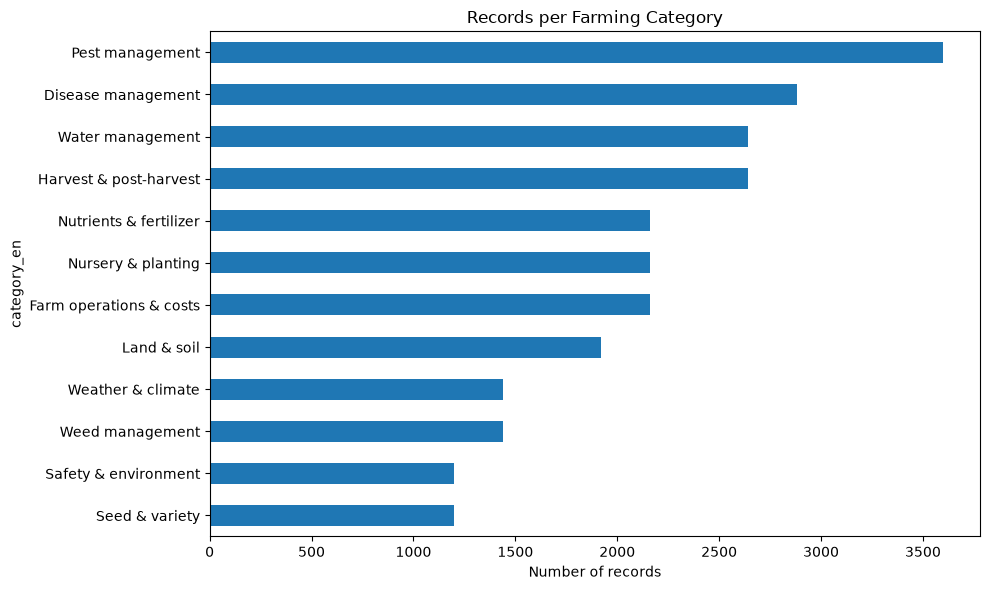

In [9]:
df["category_en"].value_counts().sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Records per Farming Category",
)

plt.xlabel("Number of records")
plt.tight_layout()
plt.show()

### Visualize Question Lengths

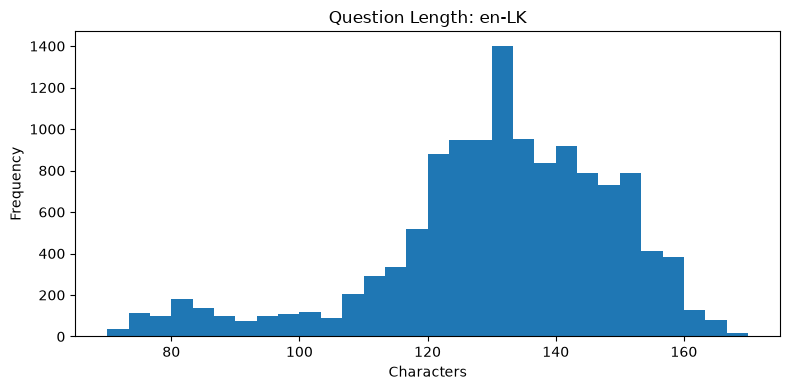

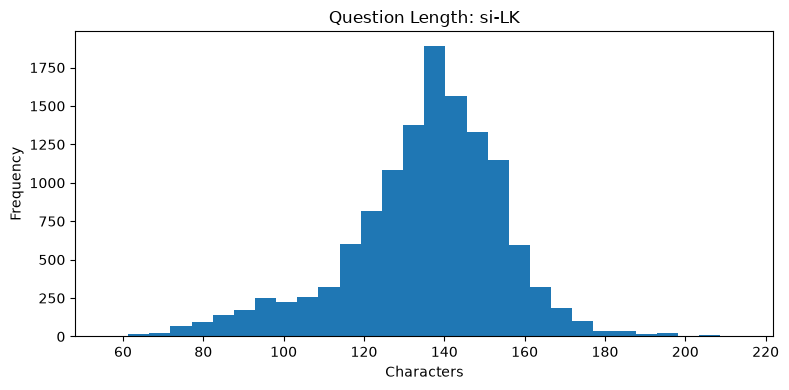

In [10]:
for language, group in df.groupby("language"):
    plt.figure(figsize=(8, 4))
    group["question_length"].plot(
        kind="hist",
        bins=30,
        title=f"Question Length: {language}",
    )
    plt.xlabel("Characters")
    plt.tight_layout()
    plt.show()

### Review Status

In [11]:
print(df["review_status"].value_counts())

review_status
not_expert_reviewed    25440
Name: count, dtype: int64


### Data Origin

In [12]:
print(df["data_origin"].value_counts())

data_origin
synthetic_template_generated_bilingual    25440
Name: count, dtype: int64
